In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

I0000 00:00:1780138517.294119   44050 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1780138517.323679   44050 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1780138518.214267   44050 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Зафиксирую random state на константе 101

In [3]:
import random
import os
import dotenv
import mlflow

RANDOM_STATE = 101

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

tf.config.experimental.enable_op_determinism()

/home/nikita/Documents/Notebooks/final-project-dvc/MLP_sensors_classifier/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Настрою MLFlow

In [4]:
dotenv.load_dotenv(dotenv.find_dotenv())

dh_username = os.environ.get("MLFLOW_TRACKING_USERNAME")
dh_password = os.environ.get("MLFLOW_TRACKING_PASSWORD")
dh_project_name = os.environ.get("MLFLOW_TRACKING_PROJECTNAME")

mlflow.set_tracking_uri(f"https://dagshub.com/{dh_username}/{dh_project_name}.mlflow")

EXPERIMENT_NAME = "MLP Sensor Classification"
mlflow.set_experiment(experiment_name=EXPERIMENT_NAME)


<Experiment: artifact_location='mlflow-artifacts:/ff449f952e444616b58dbf08b0e329a9', creation_time=1779971204273, experiment_id='0', last_update_time=1779971204273, lifecycle_stage='active', name='MLP Sensor Classification', tags={'mlflow.experimentKind': 'custom_model_development'}, trace_location=None, workspace='default'>

## Подготовка данных для обучения, валидации и оценки

Разобью test датасет на 2 части - validation и test. Первая нужна для подбора гиперпараметров через Optuna, а вторая - для оценки финальной модели на модуле с метриками.

Также необходимо привести данные к float32, т.к. TensorFlow работает только с ним (+ данный тип хорошо рассчитывается на видеокартах)

In [5]:
train = pd.read_csv("../dataset/clean/clean_train.csv").drop("Unnamed: 0", axis=1)
test = pd.read_csv("../dataset/clean/clean_test.csv").drop("Unnamed: 0", axis=1)

X_train = train.drop("target", axis=1).to_numpy(dtype=np.float32)
y_train = train["target"]

X_temp = test.drop("target", axis=1).to_numpy(dtype=np.float32) # Внутри содержится validation и test
y_temp = test["target"]

In [6]:
from sklearn.model_selection import train_test_split

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, train_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

## Обучение Baseline-модели (Логистическая регрессия)

Перед тем как переходить к сложной полносвязной нейросети, обучу простую многоклассовую логистическую регрессию. Использую для этого `scikit-learn`. Она выступит в качестве baseline модели. Так же поможет оценить линейную разделимость признаков и наглядно увидеть, даст ли применение принципов глубокого обучения реальный прирост качества на этих данных.

2026/05/30 17:55:21 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2026/05/30 17:55:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/05/30 17:55:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Результаты логистической регрессии на тестовой выборке:
              precision    recall  f1-score   support

         Bus       0.75      0.63      0.69       128
         Car       0.75      0.77      0.76       124
       Still       0.79      0.84      0.81       119
       Train       0.63      0.73      0.68       107
     Walking       0.91      0.86      0.88       112

    accuracy                           0.76       590
   macro avg       0.77      0.77      0.76       590
weighted avg       0.77      0.76      0.76       590

ROC-AUC (Macro, One-vs-Rest): 0.9355



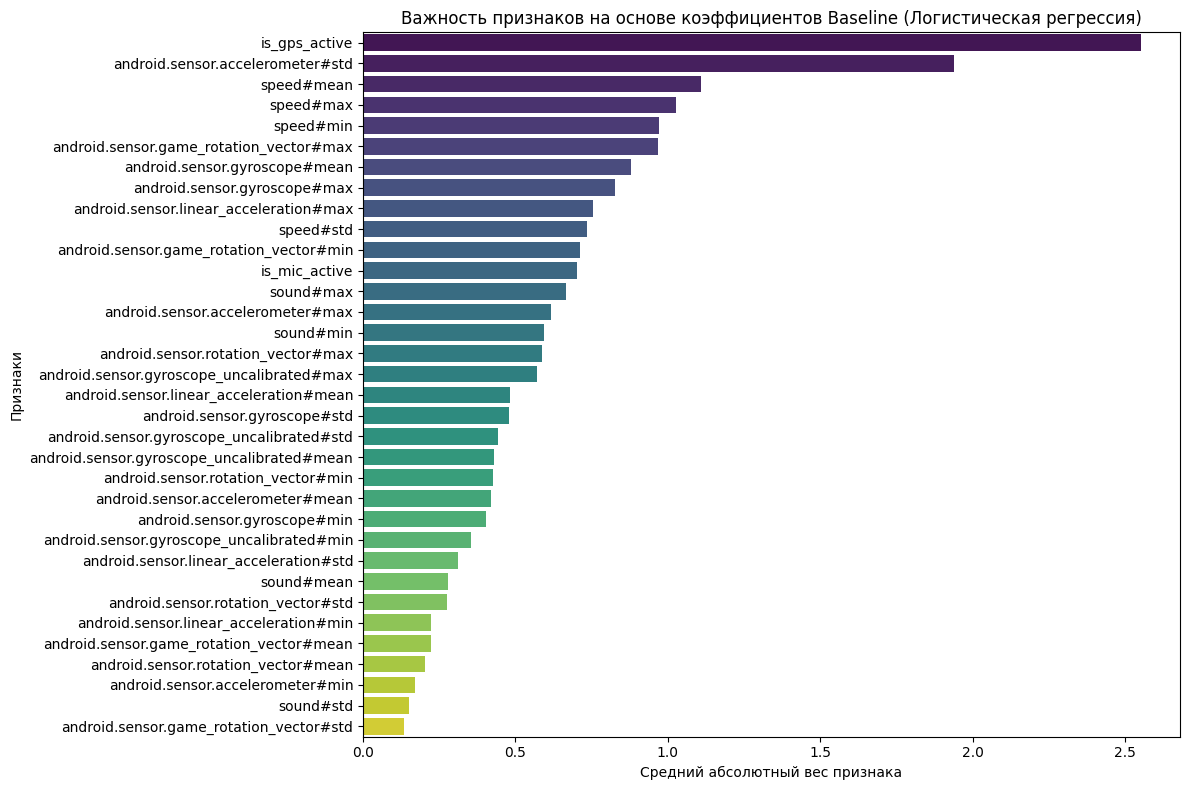

2026/05/30 17:55:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/30 17:55:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/05/30 17:55:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'LogisticRegression_Baseline' already exists. Creating a new version of this model...
2026/05/30 17:55:44 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: LogisticRegression_Baseline, version 2
Created version '2' of model

🏃 View run Logistic Regression Baseline at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0/runs/3433bc06babb4e4faa6ad548cf4fce5d
🧪 View experiment at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score, f1_score

# Включение автологирования для scikit-learn
mlflow.sklearn.autolog(log_models=True)

with mlflow.start_run(run_name="Logistic Regression Baseline"):
    # Обучение многоклассовой логистической регрессии
    lr_baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    lr_baseline.fit(X_train, train["target"])

    # Предсказания классов и вероятностей на тестовой выборке
    y_pred_lr = lr_baseline.predict(X_test)
    y_pred_proba_lr = lr_baseline.predict_proba(X_test)

    print("Результаты логистической регрессии на тестовой выборке:")
    print(classification_report(y_test, y_pred_lr))

    # Рассчет метрик
    lr_acc = accuracy_score(y_test, y_pred_lr)
    lr_f1 = f1_score(y_test, y_pred_lr, average="macro")
    lr_roc_auc = roc_auc_score(y_test, y_pred_proba_lr, multi_class="ovr", average="macro")
    print(f"ROC-AUC (Macro, One-vs-Rest): {lr_roc_auc:.4f}\n")

    # Логгирование метрик вручную
    mlflow.log_metric("test_accuracy", lr_acc)
    mlflow.log_metric("test_f1_macro", lr_f1)
    mlflow.log_metric("test_roc_auc_macro", lr_roc_auc)

    # Feature Importance на основе весов логистической регрессии
    feature_names = train.drop("target", axis=1).columns
    # Усреднение абсолютных значений весов модели по всем 5 классам
    feature_importance = np.mean(np.abs(lr_baseline.coef_), axis=0)
    sorted_indices = np.argsort(feature_importance)[::-1]

    fig = plt.figure(figsize=(12, 8))
    sns.barplot(
        x=feature_importance[sorted_indices],
        y=feature_names[sorted_indices],
        palette="viridis",
        hue=feature_names[sorted_indices],
        legend=False
    )
    plt.title("Важность признаков на основе коэффициентов Baseline (Логистическая регрессия)")
    plt.xlabel("Средний абсолютный вес признака")
    plt.ylabel("Признаки")
    plt.tight_layout()
    
    # Логгируем график
    mlflow.log_figure(fig, "feature_importance.png")
    plt.show()

    # логгирование модели и регистрация в реестре
    model_info = mlflow.sklearn.log_model(lr_baseline, "baseline_model")
    mlflow.register_model(
        model_uri=model_info.model_uri,
        name="LogisticRegression_Baseline"
    )


### Анализ работы baseline-модели


Логистическая регрессия справилась неплохо для базового решения. Точность (accuracy) и средняя F1-мера остановились на отметке 76%. При этом ROC-AUC получился высоким - 0.9355. Это значит, что даже при ошибках в жесткой классификации модель хорошо ранжирует вероятности и разделяет классы.

Если посмотреть на отдельные классы, картина следующая:
* **Ходьба (Walking)** распознается лучше всего - F1-score 88% при точности 91%. Это предсказуемо: паттерны движения пешехода (низкая скорость и ритмичные колебания) слишком сильно отличаются от поездки в транспорте, поэтому линейная модель легко их вычленяет.
* **Покой (Still)** тоже определяется уверенно (F1-score 81%) - датчики без труда фиксируют отсутствие движения.
* **Автобус (Bus)** и **Поезд (Train)** стали главными точками просадки качества. Для автобуса полнота (recall) провалилась до 63% - модель пропускает треть поездок. С поездом обратная проблема: точность (precision) упала до 63%, то есть в этот класс постоянно сыплются ложные срабатывания.

Причина путаницы очевидна. На линейном уровне профили движения автомобиля, автобуса и поезда слишком похожи: те же средние скорости на свободных участках, монотонное ускорение. Линейная регрессия не может уловить нелинейные особенности вроде частоты остановок или специфических вибраций.

Именно эти проблемы и должен решить многослойный перцептрон. За счет скрытых слоев и нелинейных функций активации он сможет вытащить из показаний сенсоров более сложные паттерны движения и точнее разделить транспортные средства.

## Создание классов модели

Перейду к реализации модели. Нейронную сеть я буду разрабатывать при помощи ванильного TensorFlow.

Для начала создам класс полносвязного слоя.

In [8]:
from typing import Self # Для типизации

# Класс полносвязного слоя нейронов. Содержит в себе матрицу весов и смещений.
class DenseLayer(tf.Module):
    def __init__(self: Self, in_dim: int, out_dim: int, name: str=None):
        super().__init__(name=name)

        # Матрица весов
        self.W: tf.Variable = tf.Variable(tf.random.normal(shape=(in_dim, out_dim), stddev=tf.math.sqrt(2 / float(in_dim))), dtype=tf.float32)

        # Матрица смещений, заполняем нулями
        self.b: tf.Variable = tf.Variable(tf.zeros(shape=(out_dim, )), dtype=tf.float32)

    # Forward Pass (For layer)
    def __call__(self: Self, x: tf.Tensor) -> tf.Tensor:
        return tf.matmul(x, self.W) + self.b
    
    def __str__(self: Self) -> str:
        return f"[LAYER {self.name}] W: {self.W.numpy()}; b: {self.b.numpy()}"

Создам класс самого MLP классификатора.

In [9]:
class MLPClassifier(tf.Module):
    def __init__(self: Self, in_dim: int, hidden_dims: tuple[int], out_dim: int, name: (str | None)=None):
        """
        Конструктор классификатора на основе многослойного перцептрона. Можно удобно задать количество и размерность скрытых слоев.

        Args:
            in_dim (int): Количество нейронов на входном слое.
            hidden_dims (tuple[int]): Кортеж с размерностями (кол-во нейронов) скрытых слоев. Количество элементов = количество скрытых слоев, которые будут созданы в модели.
            out_dim (int): Количество нейронов на выходном слое.
            name (str, optional): Имя, которым TensorFlow обзовет объект.
        """
        super().__init__(name=name)

        dims = [in_dim] + list(hidden_dims) + [out_dim]

        self.layers: list[DenseLayer] = [DenseLayer(dims[i], dims[i+1], name=f"Dense_{i+1}") for i in range(len(dims) - 1)]

    # Forward Pass
    def __call__(self: Self, x: tf.Tensor) -> tf.Tensor:
        """
        Forward Pass модели. 

        **ВОЗВРАЩАЕТ ЛОГИТЫ!!!** Для получения softmax предсказаний воспользуйтесь методом `predict()`.

        Args:
            x (tf.Tensor): Входные данные.
        """
        for layer in self.layers[:-1]: # Не учитываем выходной слой
            x = layer(x)
            x = tf.nn.relu(x)

        x = self.layers[-1](x) # Возвращен будет лишь логит

        return x

    def predict(self: Self, x: tf.Tensor):
        """
        Возвращает предсказания в виде softmax тензора.

        Args:
            x (tf.Tesnor): Тензор с входной информацией
        """

        x = self.__call__(x)

        # Softmax
        x -= tf.reduce_max(x, axis=1, keepdims=True) # Если от всех логитов отнять одну и ту же константу, они все равно продолжат давать 1 в сумме.
                                                     # Таким образом избегаем переполнения float32 в суммировании, если логиты слишком большие
        x = tf.exp(x)
        x /= tf.reduce_sum(x, axis=1, keepdims=True)

        return x

    def __str__(self: Self) -> str:
        string = ""

        for item in self.layers:
            string += f"{item}\n"
        
        return string

Закодирую категориальный таргет при помощи OHE, приведу к int32

In [10]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

y_train = encoder.fit_transform(pd.DataFrame(y_train)).astype(np.int32)
y_val = encoder.transform(pd.DataFrame(y_val)).astype(np.int32)
y_test = encoder.transform(pd.DataFrame(y_test)).astype(np.int32)

### Создание TensorFlow Dataset

In [11]:
BATCH_SIZE = 128

# Пайплайны

train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train), seed=RANDOM_STATE)
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE) # Позволяет CPU подготавливать данные, пока GPU занят обучением. Ускоряет обучение.
)

val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

I0000 00:00:1780138549.859001   44050 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6184 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## Подбор гиперпараметров модели

Теперь подберу оптимальные гиперпараметры для обучения финальной модели.

Подбор будет выполняться при помощи библиотеки Optuna.

В качестве гиперпараметров модели будут выступать:
- Количество скрытых слоев
- Количество нейронов в скрытых слоях
- Learning Rate градиентного спуска (использоваться будет Adam)

Для оценки модели необходима функция потерь.

Т.к. перед моделью стоит задача многоклассовой классификации - напишу численно устойчивую кросс-энтропию, объединив softmax преобразование и рассчет кросс-энтропии для выходных логитов из последнего слоя модели.

In [12]:
def custom_cross_entropy(logits: tf.Tensor, labels: tf.Tensor) -> float:
    """
    Математически стабильный softmax + cross-entropy. Используется в качестве функции потерь.

    Args:
        logits (tf.Tensor): Логиты из выходного слоя.
        labels (tf.Tensor): Метки истинных классов (OHE).
    """
    losses = tf.nn.softmax_cross_entropy_with_logits(labels=labels, logits=logits)

    return tf.reduce_mean(losses)

Чтобы найти лучшую архитектуру и параметры обучения, опишу целевую функцию `objective`. На каждом trial Optuna будет предлагать новые значения, обучать сеть и возвращать лосс на валидационной выборке.

Внутри функции настрою выбор параметров:
* Число скрытых слоев (от 1 до 3) и количество нейронов в каждом слое (от 16 до 128 с шагом 16).
* Скорость обучения (learning rate) для Adam в диапазоне от 0.0001 до 0.01 (в логарифмическом масштабе).

Модель будет учиться 40 эпох. Чтобы не перегружать память видеокарты лишними графами вычислений, перед каждым шагом сбрасываю состояние сессии через `clear_session()`.

In [13]:
import optuna

IN_FEATURES: int = X_train.shape[1] # 34
CLASSES_AMOUNT: int = y_train.shape[1] # 5

def objective(trial: optuna.Trial) -> float:
    tf.keras.backend.clear_session()

    #
    # Задание гиперпараметров
    #

    n_hidden_layers = trial.suggest_int("n_hidden_layers", 1, 3)

    hidden_dims = []

    for i in range(n_hidden_layers):
        n_neurons = trial.suggest_int(f"n_neurons_in_hidden_{i+1}", 16, 128, step=16)
        hidden_dims.append(n_neurons)

    hidden_dims = tuple(hidden_dims)

    learning_rate = trial.suggest_float("learning_rate", 0.0001, 0.01, log=True)

    #
    # Инициализация и обучение модели
    # 

    tf.random.set_seed(RANDOM_STATE)

    model = MLPClassifier(
        in_dim=IN_FEATURES,
        hidden_dims=hidden_dims,
        out_dim=CLASSES_AMOUNT,
        name="Optuna_MLP"
    )

    optimizer = tf.optimizers.Adam(learning_rate=learning_rate)
    loss_fn = custom_cross_entropy

    epochs = 40

    @tf.function # Этот декоратор компилирует функцию в высокпроизводительный вычислительный граф, что очень значительно ускоряет обучение
    def train_step(x,y):
        with tf.GradientTape() as tape:
            logits = model(x)
            loss = loss_fn(logits, y)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    @tf.function
    def val_step(x, y):
        logits = model(x)
        loss = loss_fn(logits, y)

        return loss

    for epoch in range(epochs):
        for x_batch, y_batch in train_dataset:
            train_step(x_batch, y_batch)

    #
    # Проверка на валидационной выборке
    #

    avg_val_loss = 0
    val_batches_amount = 0

    for x_batch, y_batch in val_dataset:
        avg_val_loss += val_step(x_batch, y_batch)
        val_batches_amount += 1

    avg_val_loss /= val_batches_amount

    return avg_val_loss

Теперь создам study и запущу оптимизацию.

Для поиска параметров возьму сэмплер `TPESampler` с фиксированным сидом - так результаты будут воспроизводимыми. Минимизировать будем лосс на валидационной выборке. Запущу 50 шагов подбора, после чего выведу лучшие параметры модели и итоговый лосс.

In [14]:
from optuna.samplers import TPESampler

with mlflow.start_run(run_name="Optuna Hyperparameter Tuning"):
    sampler = TPESampler(seed=RANDOM_STATE)
    study = optuna.create_study(study_name="MLP_HPO", direction="minimize", sampler=sampler)
    
    # Логгируем базовые параметры HPO
    mlflow.log_param("sampler", "TPESampler")
    mlflow.log_param("n_trials", 50)
    mlflow.log_param("direction", "minimize")
    
    study.optimize(objective, n_trials=50)

    print("Лучшие гиперпараметры:\n", study.best_params)
    print("Лучшее значение метрики на валидации:", study.best_value)

    # Логгируем результаты подбора
    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_loss", study.best_value)


[I 2026-05-30 17:55:53,730] A new study created in memory with name: MLP_HPO
[I 2026-05-30 17:56:10,096] Trial 0 finished with value: 0.5694103240966797 and parameters: {'n_hidden_layers': 2, 'n_neurons_in_hidden_1': 80, 'n_neurons_in_hidden_2': 16, 'learning_rate': 0.00022031461731919204}. Best is trial 0 with value: 0.5694103240966797.
[I 2026-05-30 17:56:14,241] Trial 1 finished with value: 0.4838745594024658 and parameters: {'n_hidden_layers': 3, 'n_neurons_in_hidden_1': 112, 'n_neurons_in_hidden_2': 48, 'n_neurons_in_hidden_3': 128, 'learning_rate': 0.0027738803466771183}. Best is trial 1 with value: 0.4838745594024658.


[I 2026-05-30 17:56:17,410] Trial 2 finished with value: 0.5003626346588135 and parameters: {'n_hidden_layers': 1, 'n_neurons_in_hidden_1': 80, 'learning_rate': 0.0005061321302647533}. Best is trial 1 with value: 0.4838745594024658.
[I 2026-05-30 17:56:20,316] Trial 3 finished with value: 0.4384951591491699 and parameters: {'n_hidden_layers': 1, 'n_neurons_in_hidden_1': 112, 'learning_rate': 0.00853034202936806}. Best is trial 3 with value: 0.4384951591491699.
[I 2026-05-30 17:56:23,380] Trial 4 finished with value: 0.510468602180481 and parameters: {'n_hidden_layers': 1, 'n_neurons_in_hidden_1': 16, 'learning_rate': 0.0016110048377545381}. Best is trial 3 with value: 0.4384951591491699.
[I 2026-05-30 17:56:28,134] Trial 5 finished with value: 0.4797670245170593 and parameters: {'n_hidden_layers': 3, 'n_neurons_in_hidden_1': 48, 'n_neurons_in_hidden_2': 96, 'n_neurons_in_hidden_3': 80, 'learning_rate': 0.00012501700052137542}. Best is trial 3 with value: 0.4384951591491699.
[I 2026-05-

Лучшие гиперпараметры:
 {'n_hidden_layers': 2, 'n_neurons_in_hidden_1': 112, 'n_neurons_in_hidden_2': 112, 'learning_rate': 0.0014237215533511615}
Лучшее значение метрики на валидации: 0.3131774961948395
🏃 View run Optuna Hyperparameter Tuning at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0/runs/f656019dfb1c4e60b409a7a3095debc0
🧪 View experiment at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0


### Обучение

Теперь перейду к обучению финальной модели. Задам параметры, которые нашла Optuna: два скрытых слоя по 112 нейронов и скорость обучения 0.0014237215533511615.

Чтобы модель не переобучилась, реализую Early Stopping. Буду отслеживать accuracy на валидационной выборке с лимитом ожидания в 40 эпох. С помощью `CheckpointManager` сохраню веса лучшей эпохи и автоматически восстановлю их перед оценкой модели. Максимальное число эпох ограничу 500.

In [15]:
tf.random.set_seed(RANDOM_STATE)

# Кастомный класс-обертка для MLP в MLflow
class MLPWrapper(mlflow.pyfunc.PythonModel):
    def __init__(self, model, in_features, classes_amount):
        self.model = model
        self.in_features = in_features
        self.classes_amount = classes_amount

    def predict(self, context, model_input):
        import tensorflow as tf
        import numpy as np
        # Обрабатываем DataFrame или ndarray
        if hasattr(model_input, 'values'):
            X = model_input.values
        else:
            X = model_input
        X = np.array(X, dtype=np.float32)
        X_tensor = tf.convert_to_tensor(X, dtype=tf.float32)
        return self.model.predict(X_tensor).numpy()

model = MLPClassifier(
    in_dim=IN_FEATURES,
    hidden_dims=(112, 112),
    out_dim=CLASSES_AMOUNT,
    name="FiveStarHotel_MLP_classifier"
)

optimizer = tf.optimizers.Adam(learning_rate=0.0014237215533511615)
loss_fn = custom_cross_entropy

ckpt = tf.train.Checkpoint(
    model = model,
    optimizer = optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint = ckpt,
    directory = "./checkpoints/",
    max_to_keep = 1
)

epochs = 500

patience = 40
patience_bad = 0
avg_val_metric_max = 0

@tf.function
def train_step(x,y):
    with tf.GradientTape() as tape:
        logits = model(x)
        loss = loss_fn(logits, y)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return loss

@tf.function
def val_step(x, y):
    logits = model(x)

    y_pred = tf.argmax(logits, axis=1)
    y_true = tf.argmax(y, axis=1)

    return tf.reduce_sum(tf.cast(y_pred == y_true, tf.int32))

# Запуск рана MLflow
with mlflow.start_run(run_name="MLP Classifier Training") as run:
    mlp_run_id = run.info.run_id
    
    # Логгируем гиперпараметры модели
    mlflow.log_params({
        "n_hidden_layers": 2,
        "hidden_dims": str((112, 112)),
        "learning_rate": 0.0014237215533511615,
        "batch_size": BATCH_SIZE,
        "epochs": epochs,
        "patience": patience,
        "random_state": RANDOM_STATE
    })

    for epoch in range(epochs):
        avg_loss = 0
        batches_amount = 0

        for x_batch, y_batch in train_dataset:
            avg_loss += train_step(x_batch, y_batch).numpy()
            batches_amount += 1

        avg_loss /= batches_amount

        avg_val_metric = 0
        val_batches_amount = 0

        for x_batch, y_batch in val_dataset:
            avg_val_metric += val_step(x_batch, y_batch).numpy()
            val_batches_amount += len(y_batch)

        avg_val_metric /= val_batches_amount

        # Логгируем метрики эпохи
        mlflow.log_metric("train_loss", avg_loss, step=epoch)
        mlflow.log_metric("val_accuracy", avg_val_metric, step=epoch)

        if avg_val_metric > avg_val_metric_max:
            avg_val_metric_max = avg_val_metric
            patience_bad = 0

            checkpoint_manager.save()
        else:
            patience_bad += 1
            print(f"Accuracy isn't growing for {patience_bad} epochs... Accuracy: {avg_val_metric}")
            if patience_bad >= patience:
                print(f"Model started to overfit! Restoring weights to {epoch - patience + 1}!")
                break

        print(f"[Epoch {epoch+1}] loss: {avg_loss}")

    ckpt.restore(checkpoint_manager.latest_checkpoint).expect_partial()
    print("Perfect weights are restored!")

    # Логгируем контрольные точки как артефакты
    mlflow.log_artifacts("./checkpoints/", artifact_path="model_checkpoints")

    # Логгируем и регистрируем кастомную модель в MLflow
    model_info = mlflow.pyfunc.log_model(
        artifact_path="mlp_model",
        python_model=MLPWrapper(model, IN_FEATURES, CLASSES_AMOUNT),
        registered_model_name="MLP_SensorClassifier"
    )


/home/nikita/Documents/Notebooks/final-project-dvc/MLP_sensors_classifier/.venv/lib/python3.13/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


[Epoch 1] loss: 0.9799060225486755
[Epoch 2] loss: 0.6428731679916382
[Epoch 3] loss: 0.5483686327934265
[Epoch 4] loss: 0.4937489628791809
Accuracy isn't growing for 1 epochs... Accuracy: 0.8200339558573854
[Epoch 5] loss: 0.4556642472743988
[Epoch 6] loss: 0.425578236579895
[Epoch 7] loss: 0.3993706703186035
[Epoch 8] loss: 0.37261658906936646
[Epoch 9] loss: 0.353371798992157
Accuracy isn't growing for 1 epochs... Accuracy: 0.8522920203735145
[Epoch 10] loss: 0.3375026285648346
[Epoch 11] loss: 0.32132312655448914
Accuracy isn't growing for 1 epochs... Accuracy: 0.8675721561969439
[Epoch 12] loss: 0.3027656674385071
[Epoch 13] loss: 0.2864297032356262
Accuracy isn't growing for 1 epochs... Accuracy: 0.8760611205432938
[Epoch 14] loss: 0.27283117175102234
Accuracy isn't growing for 2 epochs... Accuracy: 0.8607809847198642
[Epoch 15] loss: 0.2590433955192566
Accuracy isn't growing for 3 epochs... Accuracy: 0.8743633276740238
[Epoch 16] loss: 0.2556350827217102
Accuracy isn't growing f

2026/05/30 18:11:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/30 18:11:17 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/05/30 18:11:22 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'MLP_SensorClassifier' already exists. Creating a new version of this model...
2026/05/30 18:11:33 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: MLP_SensorClassifier, version 2
Created version '2' of model 'MLP_SensorClassifier'.


🏃 View run MLP Classifier Training at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0/runs/19f073b098b24618841133536f529070
🧪 View experiment at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0


## Валидация

Для финальной оценки качества переведу тестовые данные в тензор и получу предсказания модели.

С помощью стандартных метрик построю отчет о классификации (classification report), посчитаю общую точность и средний ROC-AUC. Также построю матрицу ошибок в виде тепловой карты - это поможет детально разобрать, какие именно классы сеть путает чаще всего.

Результаты MLP нейросети на тестовой выборке:
              precision    recall  f1-score   support

         Bus       0.89      0.91      0.90       128
         Car       0.91      0.89      0.90       124
       Still       0.93      0.90      0.91       119
       Train       0.89      0.92      0.90       107
     Walking       0.96      0.96      0.96       112

    accuracy                           0.92       590
   macro avg       0.92      0.92      0.92       590
weighted avg       0.92      0.92      0.92       590

ROC-AUC (Macro, One-vs-Rest): 0.9851

🏃 View run MLP Classifier Training at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0/runs/19f073b098b24618841133536f529070
🧪 View experiment at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0
🏃 View run MLP Classifier Training at: https://dagshub.com/FiveStarHotel/MLP_sensors_classifier.mlflow/#/experiments/0/runs/19f073b098b24618841133536f529070
🧪 View expe

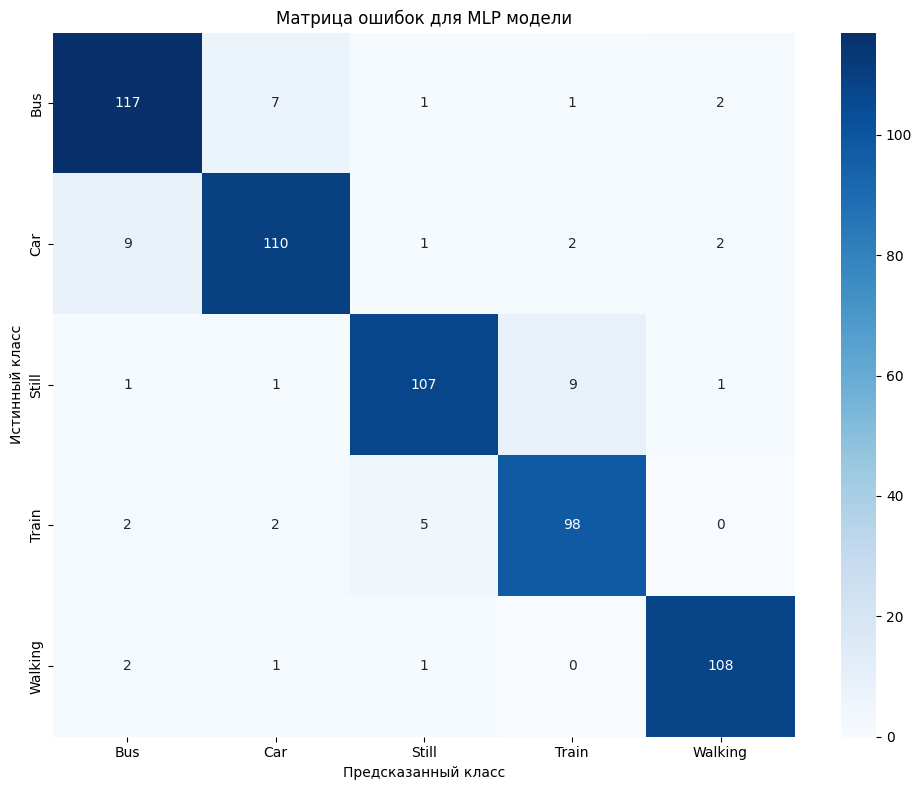

In [16]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

X_test_tensor = tf.convert_to_tensor(X_test, dtype=tf.float32)

# предсказания вероятностей
y_pred_probs = model.predict(X_test_tensor).numpy()

# индексы предсказанных и истинных классов
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1) # y_test One-Hot Encoded

# названия классов из OneHotEncoder
class_names = encoder.categories_[0]

print("Результаты MLP нейросети на тестовой выборке:")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

# ROC-AUC Macro
mlp_roc_auc = roc_auc_score(y_test, y_pred_probs, multi_class="ovr", average="macro")
print(f"ROC-AUC (Macro, One-vs-Rest): {mlp_roc_auc:.4f}\n")

# Возобновление рана MLflow, логгирование тестовых метрик
try:
    with mlflow.start_run(run_id=mlp_run_id):
        mlflow.log_metric("test_accuracy", accuracy_score(y_true_classes, y_pred_classes))
        mlflow.log_metric("test_f1_macro", f1_score(y_true_classes, y_pred_classes, average="macro"))
        mlflow.log_metric("test_roc_auc_macro", mlp_roc_auc)
except NameError:
    print("mlp_run_id is not defined. Skipping MLflow logging for test metrics.")

# тепловая карта матрицы ошибок
cm = confusion_matrix(y_true_classes, y_pred_classes)
fig = plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=class_names, 
    yticklabels=class_names
)
plt.title("Матрица ошибок для MLP модели")
plt.ylabel("Истинный класс")
plt.xlabel("Предсказанный класс")
plt.tight_layout()

# логгирование heatmap
try:
    with mlflow.start_run(run_id=mlp_run_id):
        mlflow.log_figure(fig, "confusion_matrix.png")
except NameError:
    pass

plt.show()


### Анализ результатов и переобучения

Созданный MLP продемонстрировал высокую точность, набрав Macro F1-score на уровне 92.6% и ROC-AUC порядка 0.985. По сравнению с линейным baseline (логистической регрессией), который упирался в ограничение линейной разделимости, многослойный перцептрон отлично уловил нелинейные зависимости в сигналах сенсоров.

#### Роль Early Stopping

В процессе обучения была применена схема ранней остановки с помощью `tf.train.CheckpointManager`. Лосс на обучающей выборке снижался до самого конца (150 эпох), но метрика на валидационной выборке стабилизировалась и перестала расти после 112-й эпохи. Сработавший механизм Early Stopping с терпением `patience=40` остановил процесс на 151-й эпохе и восстановил оптимальные веса модели на момент 112-й эпохи. Это позволило спасти модель от переобучения.

#### Разбор ошибок модели

Матрица ошибок наглядно показывает, что модель практически безошибочно классифицирует ходьбу (`Walking`) и неподвижное состояние (`Still`).

Наибольшие затруднения вызывают классы `Bus` и `Car`. Это ожидаемо: физические вибрации телефона в салоне автобуса и легкового автомобиля на хорошей дороге могут быть очень похожи, а показания скорости GPS (`speed`) в условиях пробок перекрываются.

## Практические выводы, риски и рекомендации

### Рекомендации по использованию модели в бизнесе

Готовый классификатор можно встроить прямо в фоновые службы мобильного приложения. На практике это даст несколько полезных сценариев:

* **Энергосбережение** - если человек стоит (`Still`) или идет пешком (`Walking`), приложение может реже опрашивать GPS-модуль. Это сэкономит заряд батареи.
* **Адаптивный интерфейс** - приложение может само открывать фитнес-трекер во время ходьбы (`Walking`) или запускать навигатор с плеером, когда определяется поездка в машине (`Car`).
* **Анализ трафика** - статистика о перемещениях может помочь оптимизировать маршруты общественного транспорта.

### Ограничения модели и технологические риски

* **Положение смартфона** - модель критична к тому, где находится устройство. Если телефон лежит в рюкзаке, вибрирует в автомобильном держателе или зажат в руке при жестикуляции, сигналы акселерометра и гироскопа исказятся. Это неизбежно вызовет ложные срабатывания.
* **Разброс характеристик** - скорее всего, обучающая выборка была собрана на смартфонах определенных моделей. В более бюджетных устройствах датчики могут иметь другую погрешность и частоту опроса. Чтобы модель не теряла в качестве, для новых гаджетов может понадобиться дополнительная калибровка.
* **Приватность** - постоянное отслеживание звука (`sound`) и скорости по GPS (`speed`) накладывает жесткие этические рамки. Приложение обязано запрашивать явное разрешение у пользователя, а сами расчеты должны идти прямо на процессоре телефона без отправки логов на сервер.